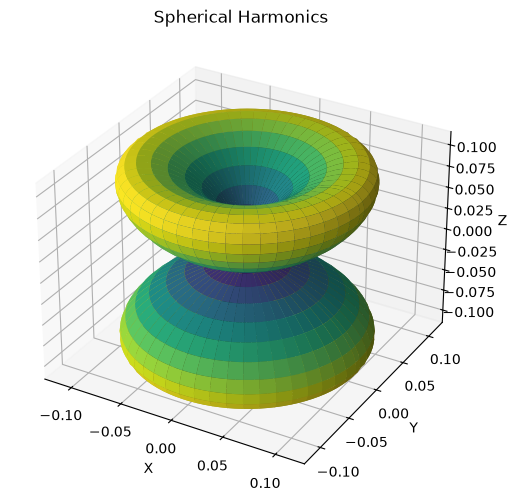

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import math


def legendre(l, m, x):

    p = np.ones_like(x)

    for i in range(1, m + 1):
        p = -(2*i - 1) * np.sqrt(1 - x**2) * p

    if l == m:
        return p

    p1 = (2*m + 1) * x * p

    if l == m + 1:
        return p1

    for n in range(m + 2, l + 1):
        p2 = ((2*n - 1)*x*p1 - (n+m-1)*p)/(n-m)
        p = p1
        p1 = p2

    return p1



def spherical_harmonic(l, m, theta, phi):

    m1 = abs(m)
    x = np.cos(theta)

    P = legendre(l, m1, x)

    A = np.sqrt((2*l+1)*math.factorial(l-m1) /
                (4*np.pi*math.factorial(l+m1)))

    Y = A * P * np.exp(1j*m1*phi)

    if m < 0:
        Y = (-1)**m1 * np.conjugate(Y)

    return Y



l = 2
m = 1


theta = np.linspace(0, np.pi, 100)
phi = np.linspace(0, 2*np.pi, 100)

theta, phi = np.meshgrid(theta, phi)


Y = spherical_harmonic(l, m, theta, phi)
density = np.abs(Y)**2


x = density * np.sin(theta) * np.cos(phi)
y = density * np.sin(theta) * np.sin(phi)
z = density * np.cos(theta)


fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

surface = ax.plot_surface(
    x, y, z,
    facecolors=plt.cm.viridis(density/np.max(density)),
    linewidth=0
)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_title("Spherical Harmonics")

plt.show()
